In [1]:
!pip install python-docx  #extract text from word resume

ERROR: Invalid requirement: '#extract': Expected package name at the start of dependency specifier
    #extract
    ^


In [2]:
# Library to work with files and folders
import os

# Library to create and manipulate dataframes
import pandas as pd

# Library to read DOCX files
from docx import Document

# Library for converting DOC files to DOCX using Microsoft Word
import win32com.client as win32

In [3]:
dataset_path = r"C:\Users\HP\Downloads\P691 Dataset\P637 Dataset\Resumes_Docx"

In [4]:
# Display all category folders
folders = os.listdir(dataset_path)

print(folders)

['Peoplesoft', 'Peoplesoft Resume', 'React Developer', 'SQL Developer', 'workday']


In [5]:
# Count total resumes

total_files = 0

for folder in folders:

    folder_path = os.path.join(dataset_path, folder)

    total_files += len(os.listdir(folder_path))

print("Total Files :", total_files)

Total Files : 80


In [6]:
# Count DOC and DOCX files

doc_count = 0
docx_count = 0

for folder in folders:

    folder_path = os.path.join(dataset_path, folder)

    for file in os.listdir(folder_path):

        if file.endswith(".doc") and not file.endswith(".docx"):
            doc_count += 1

        elif file.endswith(".docx"):
            docx_count += 1

print("DOC :", doc_count)
print("DOCX :", docx_count)

DOC : 26
DOCX : 53


In [7]:
import os

# Original dataset path
dataset_path = r"C:\Users\HP\Downloads\P691 Dataset\P637 Dataset\Resumes_Docx"

# New folder to store converted files
converted_path = r"C:\Users\HP\Downloads\P691 Dataset (2)\P637 Dataset\Converted_Resumes"

# Create folder if it doesn't exist
os.makedirs(converted_path, exist_ok=True)

print("Converted_Resumes folder created successfully.")

Converted_Resumes folder created successfully.


In [8]:
import shutil

# Get all category folders
folders = os.listdir(dataset_path)

# Copy each category folder
for folder in folders:

    source_folder = os.path.join(dataset_path, folder)

    destination_folder = os.path.join(converted_path, folder)

    shutil.copytree(source_folder, destination_folder, dirs_exist_ok=True)

print("All folders copied successfully.")   #convert the folder structure into converted resumes

All folders copied successfully.


In [9]:
import os
import win32com.client

# Open Microsoft Word
word = win32com.client.Dispatch("Word.Application")
word.Visible = False     #hide microsoft word running in the background without displaying 

for folder in folders:

    folder_path = os.path.join(converted_path, folder)

    for file in os.listdir(folder_path):

        # Convert only .doc files
        if file.lower().endswith(".doc") and not file.lower().endswith(".docx"):

            doc_path = os.path.join(folder_path, file)

            docx_path = doc_path + "x"

            try:

                document = word.Documents.Open(doc_path)

                document.SaveAs(docx_path, FileFormat=16)

                document.Close()

                print(f"Converted : {file}")

            except Exception as e:

                print(f"Could not convert : {file}")
                print(e)

word.Quit()

print("Conversion Completed.")

Converted : Peoplesoft Admin_G Ananda Rayudu.doc
Converted : Peoplesoft Admin_Gangareddy.doc
Converted : Peoplesoft Admin_Priyanka Ramadoss.doc
Converted : Peoplesoft Admin_srinivasarao.doc
Converted : Peoplesoft Admin_Vinod Akkala.doc
Converted : PeopleSoft DBA_Ganesh Alladi.doc
Converted : Peoplesoft Finance_Arun Venu.doc
Converted : Peoplesoft Finance_Pritam Biswas.doc
Converted : Peoplesoft Finance_Rahul Ahuja.doc
Converted : Peoplesoft FSCM_R Ahmed.doc
Converted : React Developer_PavasGoswami.doc
Converted : React Developer_Vinay Reddy.doc
Converted : React JS Developer_AnjaniPriyadarshini.doc
Converted : Nazeer Basha.doc
Converted : Priyanka L.doc
Converted : Tatikonda Kiran Kumar.doc
Converted : Hari Krishna M_Hexaware.doc
Converted : Harikrishna Akula_Hexaware.doc
Converted : Hima Mendu_Hexaware.doc
Converted : J. Sumanth Royal_Hexaware.doc
Converted : Madeeswar A_Hexaware.doc
Converted : Naresh Babu Cherukuri_Hexaware.doc
Converted : Punugoti Swetha_Hexaware.doc
Converted : Sh

In [10]:

doc_count = 0
docx_count = 0

for folder in folders:

    folder_path = os.path.join(converted_path, folder)

    for file in os.listdir(folder_path):

        if file.lower().endswith(".doc") and not file.lower().endswith(".docx"):
            doc_count += 1

        elif file.lower().endswith(".docx"):
            docx_count += 1

print("DOC Files :", doc_count)
print("DOCX Files:", docx_count)

DOC Files : 26
DOCX Files: 79


In [11]:
# Path of converted dataset
dataset_path = r"C:\Users\HP\Downloads\P691 Dataset (2)\P637 Dataset\Converted_Resumes"

In [12]:
folders = os.listdir(dataset_path)

In [13]:
# Function to extract text from a DOCX resume

def extract_resume_text(file_path):

    # Open the Word document
    doc = Document(file_path)

    # Variable to store resume text
    text = ""

    # Read every paragraph
    for paragraph in doc.paragraphs:
        text += paragraph.text + "\n"

    return text     
#open word document read all pargraph  and combine into a single string and return complete resume 

In [14]:
# Lists to store extracted data
resume_text = []
category = []

In [15]:
# Corrupted resume to skip
skip_file = "Peoplesoft Admin_G Ananda Rayudu.docx"

# Loop through every category folder
for folder in folders:

    folder_path = os.path.join(dataset_path, folder)

    # Loop through every resume
    for file in os.listdir(folder_path):

        # Read only DOCX files
        if file.lower().endswith(".docx"):

            # Skip the corrupted resume
            if file == skip_file:
                print(f"Skipped: {file}")
                continue

            file_path = os.path.join(folder_path, file)

            try:
                text = extract_resume_text(file_path)

                resume_text.append(text)
                category.append(folder)

            except Exception as e:
                print(f"Error reading {file}")
                print(e)

Skipped: Peoplesoft Admin_G Ananda Rayudu.docx
Skipped: Peoplesoft Admin_G Ananda Rayudu.docx


In [16]:
df = pd.DataFrame({
    "Resume_Text": resume_text,
    "Category": category
})

In [17]:
df.shape

(77, 2)

In [18]:
df["Category"].value_counts()

Category
React Developer      23
workday              21
Peoplesoft Resume    19
SQL Developer        14
Name: count, dtype: int64

In [19]:
# Display first five records
df.head()

,Resume_Text,Category
0,Anubhav Kumar Singh\t\t\n\n To work in a gl...,Peoplesoft Resume
1,PeopleSoft Database Administrator\n ...,Peoplesoft Resume
2,Murali\n\nExperience Summary \n\nI have 6 year...,Peoplesoft Resume
3,"Priyanka Ramadoss\n61/46, MountPleasant, \nCoo...",Peoplesoft Resume
4,\n\n\n\n\n\n\n\n\n\n\n\n\n\nPROFILE SUMMARY\n\...,Peoplesoft Resume


In [20]:
# Display last five records
df.tail()

,Resume_Text,Category
72,\tWorkday Integration Consultant\n\nName ...,workday
73,Seeking suitable positions in Workday HCM as ...,workday
74,\nWORKDAY | HCM | FCM\nName \t\t: Kumar S.S\nR...,workday
75,Venkateswarlu.B\t\t\t\t\t\t\t\tWorkday Consult...,workday
76,...,workday


In [21]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Resume_Text  77 non-null     object
 1   Category     77 non-null     object
dtypes: object(2)
memory usage: 1.3+ KB


In [22]:
df.describe()

,Resume_Text,Category
count,77,77
unique,77,4
top,Anubhav Kumar Singh\t\t\n\n To work in a gl...,React Developer
freq,1,23


In [23]:
# Check missing values
df.isnull().sum()

Resume_Text    0
Category       0
dtype: int64

In [24]:
# Check duplicate records
df.duplicated().sum()

np.int64(0)

In [25]:
# Calculate the length of each resume in characters
df["Resume_Length"] = df["Resume_Text"].apply(lambda x: len(str(x)))

In [26]:
# Calculate the number of words in each resume
df["Word_Count"] = df["Resume_Text"].apply(lambda x: len(str(x).split()))

In [27]:
df.head()

,Resume_Text,Category,Resume_Length,Word_Count
0,Anubhav Kumar Singh\t\t\n\n To work in a gl...,Peoplesoft Resume,7257,934
1,PeopleSoft Database Administrator\n ...,Peoplesoft Resume,6768,786
2,Murali\n\nExperience Summary \n\nI have 6 year...,Peoplesoft Resume,3982,528
3,"Priyanka Ramadoss\n61/46, MountPleasant, \nCoo...",Peoplesoft Resume,3709,488
4,\n\n\n\n\n\n\n\n\n\n\n\n\n\nPROFILE SUMMARY\n\...,Peoplesoft Resume,3647,505


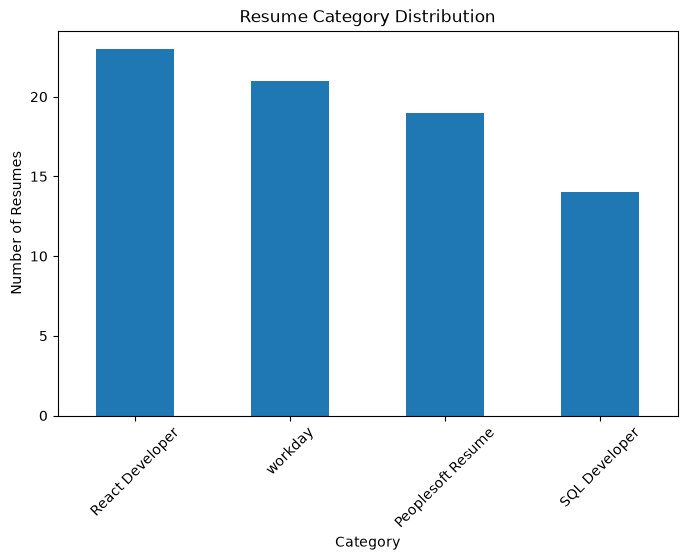

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

df["Category"].value_counts().plot(kind="bar")

plt.title("Resume Category Distribution")

plt.xlabel("Category")

plt.ylabel("Number of Resumes")

plt.xticks(rotation=45)

plt.show()

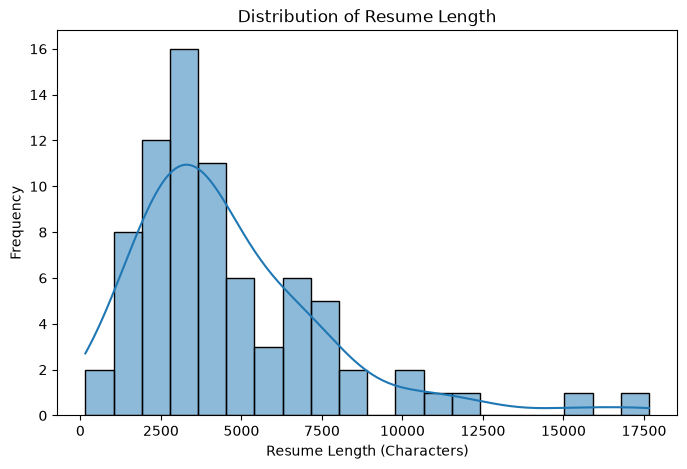

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.histplot(data=df, x="Resume_Length", bins=20, kde=True)

plt.title("Distribution of Resume Length")
plt.xlabel("Resume Length (Characters)")
plt.ylabel("Frequency")

plt.show()

In [30]:
#most frequent words 
from collections import Counter

text = " ".join(df["Resume_Text"]).lower().split()

word_freq = Counter(text)

print(word_freq.most_common(20))

[('and', 2587), ('the', 1277), ('in', 1194), ('to', 1014), ('of', 916), ('on', 592), ('for', 592), ('experience', 520), (':', 440), ('with', 394), ('as', 386), ('using', 364), ('workday', 344), ('peoplesoft', 327), ('application', 325), ('from', 290), ('a', 288), ('data', 282), ('server', 248), ('business', 241)]


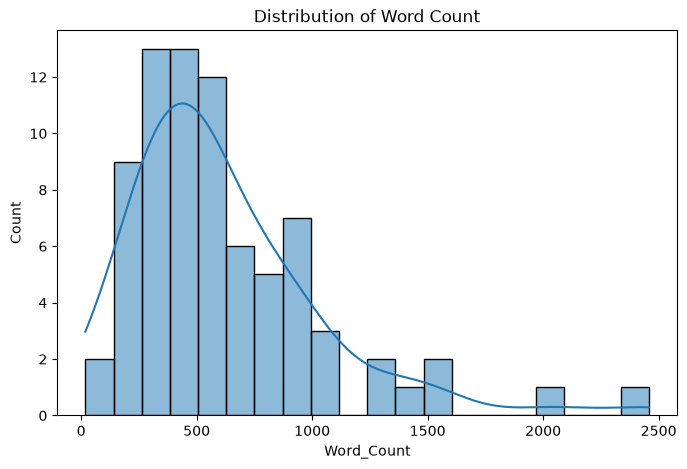

In [31]:
plt.figure(figsize=(8,5))
sns.histplot(df["Word_Count"], bins=20, kde=True)
plt.title("Distribution of Word Count")
plt.show()

In [32]:
# Regular expressions
import re

# String operations
import string

# NLTK libraries
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

In [33]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [34]:
# English stopwords
stop_words = set(stopwords.words("english"))

# Initialize lemmatizer
lemmatizer = WordNetLemmatizer()

In [35]:
def preprocess_text(text):

    # Convert to string
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', ' ', text)

    # Remove phone numbers
    text = re.sub(r'\b\d{10,15}\b', ' ', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # Remove numbers
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Tokenization
    words = word_tokenize(text)

    # Remove stopwords and perform lemmatization
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    # Join words back into text
    return " ".join(words)

In [36]:
# Create a new cleaned text column
df["Clean_Resume"] = df["Resume_Text"].apply(preprocess_text)

In [37]:
df[["Resume_Text", "Clean_Resume"]].head()

,Resume_Text,Clean_Resume
0,Anubhav Kumar Singh\t\t\n\n To work in a gl...,anubhav kumar singh work globally competitive ...
1,PeopleSoft Database Administrator\n ...,peoplesoft database administrator gangareddy p...
2,Murali\n\nExperience Summary \n\nI have 6 year...,murali experience summary year experience work...
3,"Priyanka Ramadoss\n61/46, MountPleasant, \nCoo...",priyanka ramadoss mountpleasant coonoor nilgir...
4,\n\n\n\n\n\n\n\n\n\n\n\n\n\nPROFILE SUMMARY\n\...,profile summary overall year ’ experience peop...


In [38]:
df.to_csv("Cleaned_Resume_Dataset.csv", index=False)

print("Preprocessing completed successfully!")

Preprocessing completed successfully!


# Steps to perform model building and model evaluation


1.Feature Extraction (TF-IDF) 


2.Label Encoding

3.Train-Test Split

4.Model Training

5.Model Evaluation 

# FEATURE EXTRACTION USING TF-IDF


In [39]:
#import libraries
from sklearn.feature_extraction.text import TfidfVectorizer     #to convert text into numerical feature 

In [40]:
#create TF-IDF Object
tfidf = TfidfVectorizer(max_features=5000)

In [41]:
#convert clean text into numerical features 
X = tfidf.fit_transform(df["Clean_Resume"])

In [42]:
#check shape
print(X.shape)   #shows number of resumes, and number of unique words selected by TF-IDF 

(77, 3792)


# LABEL ENCODING 

In [43]:
#Import libraries
from sklearn.preprocessing import LabelEncoder 

In [45]:
label_encoder=LabelEncoder() # create object  that convert category names into numbers 
y=label_encoder.fit_transform(df["Category"])  #encode the target variable 
print(y) # display encoded variables

  

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3]


In [47]:
#VIEW THE MAPPING
mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))

print(mapping)

{'Peoplesoft Resume': np.int64(0), 'React Developer': np.int64(1), 'SQL Developer': np.int64(2), 'workday': np.int64(3)}


# Train - Test and Split

In [50]:
from sklearn.model_selection import train_test_split

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
#check shapes
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (61, 3792)
X_test shape : (16, 3792)
y_train shape: (61,)
y_test shape : (16,)


# MODEL BUILDING and MODEL EVALUATION
# LOGISTIC REGRESSION
1.train model 
2.make predictions
3. evaluate the model
4.explain the result


In [53]:
#Import libraries
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import( accuracy_score, classification_report, confusion_matrix)


In [55]:
lr_model=LogisticRegression(random_state=42) #create object 
lr_model.fit(X_train,y_train) #train the model
y_pred =lr_model.predict(X_test) #predict on test data


In [56]:
#calculate Accuracy
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)

Accuracy: 0.875


In [57]:
#classification report 
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      0.60      0.75         5
           1       0.60      1.00      0.75         3
           2       1.00      1.00      1.00         4
           3       1.00      1.00      1.00         4

    accuracy                           0.88        16
   macro avg       0.90      0.90      0.88        16
weighted avg       0.93      0.88      0.88        16



In [58]:
#confusion matrix
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[3 2 0 0]
 [0 3 0 0]
 [0 0 4 0]
 [0 0 0 4]]


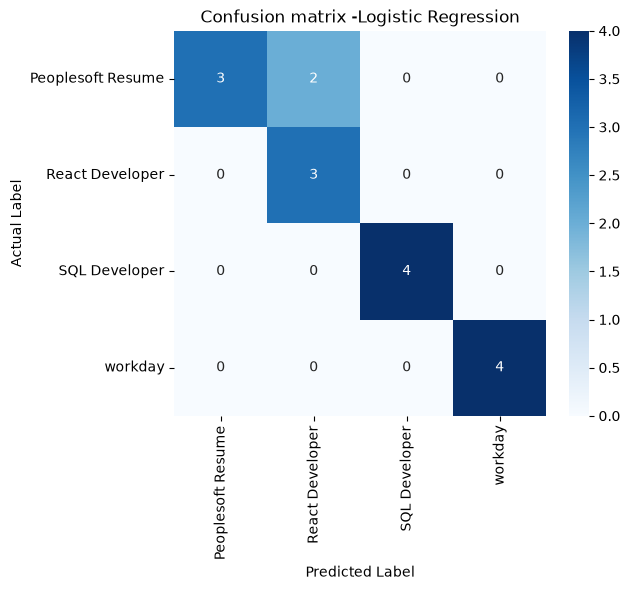

In [62]:
#plot confusion matrix 
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=label_encoder.classes_,yticklabels=label_encoder.classes_)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion matrix -Logistic Regression")
plt.show()

"The Logistic Regression model achieved an accuracy of 87.5% on the test dataset. it classified SQL Developer and workday resumes with 100%precision and recall. A few peoplesoft Resume instances were misclassified as React Developer,but overall the model performed well and demonstrated strong classification capability ."

# multinomial Naive Bayes

In [63]:
#import libraries
from sklearn.naive_bayes import MultinomialNB    #multinomialNB-naive bayes classifier for text data
from sklearn.metrics import accuracy_score,classification_report, confusion_matrix

In [65]:
nb_model=MultinomialNB() #create the model
nb_model.fit(X_train,y_train)  #train the model
y_pred_nb=nb_model.predict(X_test)


In [69]:
#calculate accuracy
accuracy_nb=accuracy_score(y_test,y_pred_nb)
print("Accuracy:",accuracy_nb)

Accuracy: 0.9375


In [70]:
print(classification_report(y_test,y_pred_nb))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         3
           2       1.00      0.75      0.86         4
           3       0.80      1.00      0.89         4

    accuracy                           0.94        16
   macro avg       0.95      0.94      0.94        16
weighted avg       0.95      0.94      0.94        16



In [71]:
cm_nb=confusion_matrix(y_test,y_pred_nb)
print(cm_nb)

[[5 0 0 0]
 [0 3 0 0]
 [0 0 3 1]
 [0 0 0 4]]


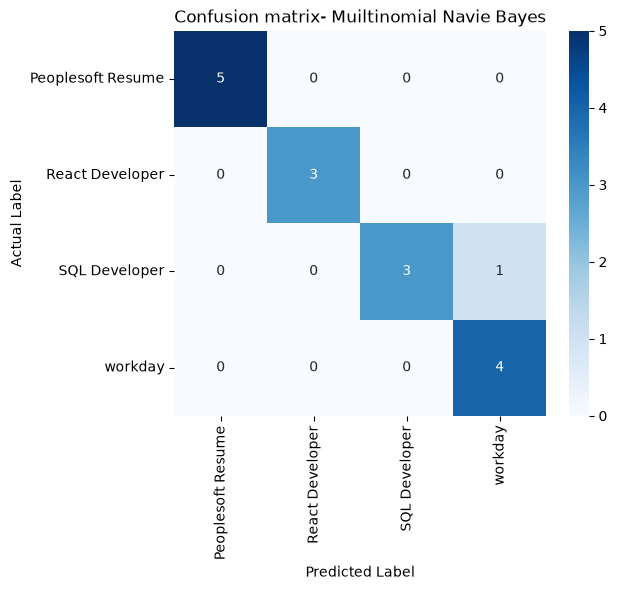

In [74]:
#plot confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6,5))
sns.heatmap(cm_nb,annot=True, fmt="d",cmap="Blues",xticklabels=label_encoder.classes_,yticklabels=label_encoder.classes_)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion matrix- Muiltinomial Navie Bayes")
plt.show()

#conculsion
"The Multinomial Naive Bayes model achieved an accuracy of 93.75% on the test dataset . it correctly classified all peoplesoft resume , React developer and workdat resumes, with only one sql developer resume being misclassified as workdat. overall, the model demonstrated excellent performance for resume classification."

# linear Support Vector Classifier 


In [75]:
# import libraries
from sklearn.svm import LinearSVC

In [76]:
svc_model=LinearSVC(random_state=42)
svc_model.fit(X_train,y_train)
y_pred_svc=svc_model.predict(X_test)

In [77]:
accuracy_svc=accuracy_score(y_test,y_pred_svc)
print(accuracy_svc)

1.0


In [78]:
print(classification_report(y_test,y_pred_svc))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         4
           3       1.00      1.00      1.00         4

    accuracy                           1.00        16
   macro avg       1.00      1.00      1.00        16
weighted avg       1.00      1.00      1.00        16



In [79]:
cm_svc=confusion_matrix(y_test,y_pred_svc)
print(cm_svc)

[[5 0 0 0]
 [0 3 0 0]
 [0 0 4 0]
 [0 0 0 4]]


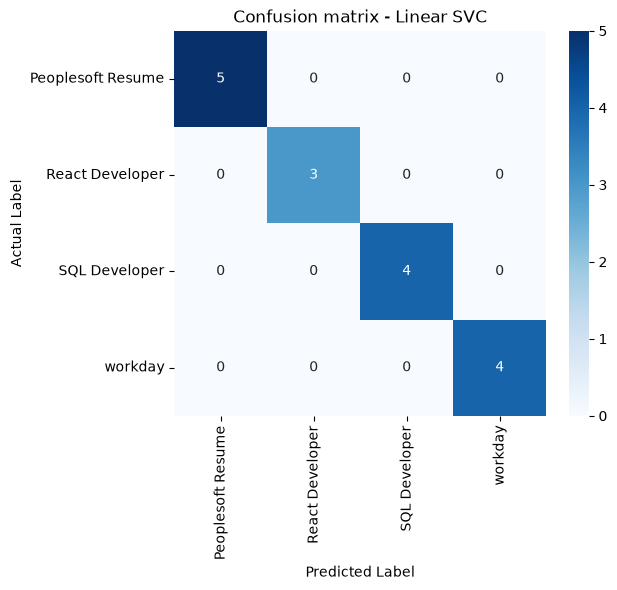

In [81]:
#plot confusion matrix
plt.figure(figsize=(6,5))
sns.heatmap(cm_svc,annot=True, fmt="d", cmap="Blues",xticklabels=label_encoder.classes_,yticklabels=label_encoder.classes_)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion matrix - Linear SVC")
plt.show()

#conclusion:
"The Linear SVC model achieved 100% accuracy on the test dataset. it correctly classified every resume without any misclassification . all categories obtained perfect precision, recall and F1-score , making Linear SVC the best_performing  model for this resume classification project ."

In [82]:
#compare all models 
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Multinomial Naive Bayes",
        "Linear SVC"
    ],
    "Accuracy": [
        accuracy,
        accuracy_nb,
        accuracy_svc
    ]
})

# Convert accuracy to percentage
comparison["Accuracy (%)"] = comparison["Accuracy"] * 100

# Display the comparison
comparison

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.8750,87.50
1,Multinomial Naive Bayes,0.9375,93.75
2,Linear SVC,1.0000,100.00


conclusion:"Three classification models were trained and evaluated using the same training and testing datasets. Logistic Regression achieved an accuracy of 87.50%, Multinomial Naive Bayes achieved 93.75%, and Linear SVC achieved 100% accuracy. Among the three models, Linear SVC performed the best and was selected as the final model for deployment.

# final output for model building and model evaluation
1.feature Extraction
2.Label Encoding
3.Train-Test split 
4.model Building 
  *Logistic Regression
  *multinomial Naive Bayes
  *linear SVC 
5.Model Evaluation
 *Accuracy
 *precision
 *Recall
 *F1-Score
 *Confusion matrix 
6.Model comparision
7.Find Model Selection 

# Save the Model


In [83]:
import pickle
#save the trained linear SVC model
with open("linear_svc_model.pkl","wb") as file:
    pickle.dump(svc_model,file)
print("Model saved successfully!")

Model saved successfully!


In [84]:
#save TF-IDF Vectorizer
with open("tfidf_vectorizer.pkl","wb") as file:
    pickle.dump(tfidf,file)
print("TF -IDF Vectorizer saved successfully!")

TF -IDF Vectorizer saved successfully!


In [85]:
#save the Label Encoder
with open("label_encoder.pkl","wb") as file:
    pickle.dump(label_encoder,file)
print("Label Encoder saved successfully!")

Label Encoder saved successfully!
